# Simulations: Random Walk

This notebook runs a Monte Carlo simulation on a pure unit root Random Walk process:
$$y_t = y_{t-1} + \varepsilon_t, \quad \varepsilon_t \overset{\text{iid}}{\sim} \mathcal{N}(0, \sigma^2), \quad y_0 = 0$$
evaluated across multiple forecast horizons $h \in [1, 3, 7, 14, 30]$ over 100 Monte Carlo replications.

### Experimental Design
1. **Naive Baseline**: $\hat{y}_{t+h \mid t} = y_t$ (theoretically optimal conditional expectation $\mathbb{E}[y_{t+h} \mid \mathcal{F}_t] = y_t$).
2. **ARIMA(1,1,1)**: over-parameterized integrated model ($d=1$) without trend, evaluating parameter redundancy/cancellation on $\Delta y_t$ ($\phi_1 \approx -\theta_1$).
3. **Random Forest on Levels**: recursive non-linear regression on raw levels with lag features ($X_t = [y_{t-1}]$ and $X_t = [y_{t-1}, y_{t-2}, y_{t-3}, y_{t-4}]$), testing the bounded extrapolation failure of tree models when the walk wanders outside the training range $[\min(y_{\text{train}}), \max(y_{\text{train}})]$.
4. **Random Forest on Differences with Inversion**: recursive non-linear regression on stationary first differences ($\Delta y_t$) with difference inversion (`diffinv`: $\hat{y}_{t+h \mid t} = y_t + \sum_{k=1}^h \widehat{\Delta y}_{t+k}$), testing whether differencing rescues trees from extrapolation failure and tracks the Naive baseline.

## 1. Setup and Parameters

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

# Universal modular simulation engine and DGPs
from src.simulations import (
    generate_random_walk,
    model_naive_multistep,
    model_arima_rw_multistep,
    model_rf_levels_multistep,
    model_rf_diff_multistep,
    run_simulation_multistep,
)
from src.ML_models import direct_lags

FIG_DIR = Path("figures/simulations")
FIG_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR = Path("../Results/Simulations")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Simulation parameters calibrated to Careggi dataset dimensions
N_SAMPLES = 2542
N_TEST = 364
N_SIM = 100
SIGMA = 1.0
BASE_SEED = 42
HORIZONS = [1, 3, 7, 14, 30]


## 2. Monte Carlo Simulation Execution

In [2]:
print(f"Executing {N_SIM} Monte Carlo replications (T={N_SAMPLES}, Test={N_TEST}) for Random Walk across horizons {HORIZONS}...")

models_rw = {
    "naive": model_naive_multistep(period=1),
    "arima111": model_arima_rw_multistep(
        order=(1, 1, 1),
        trend="n",
        maxiter=200,
    ),
    "rf_lvl_1lag": model_rf_levels_multistep(lags=[1], n_estimators=100),
    "rf_lvl_4lags": model_rf_levels_multistep(lags=[1, 2, 3, 4], n_estimators=100),
    "rf_diff_1lag": model_rf_diff_multistep(lags=[1], d=1, n_estimators=100),
    "rf_diff_4lags": model_rf_diff_multistep(lags=[1, 2, 3, 4], d=1, n_estimators=100),
}

df_results = run_simulation_multistep(
    dgp_fn=generate_random_walk,
    models=models_rw,
    n_sim=N_SIM,
    n_samples=N_SAMPLES,
    n_test=N_TEST,
    horizons=HORIZONS,
    sigma=SIGMA,
    base_seed=BASE_SEED,
    n_jobs=-1,
)

csv_path = RESULTS_DIR / "rw_results_100.csv"
df_results.to_csv(csv_path, index=False)
print(f"Replication results successfully saved to: {csv_path}")


Executing 100 Monte Carlo replications (T=2542, Test=364) for Random Walk across horizons [1, 3, 7, 14, 30]...


Replication results successfully saved to: ../Results/Simulations/rw_results_100.csv


## 3. Summary Statistics and Model Comparison

In [3]:
models_list = [
    ("Naive Baseline", "naive"),
    ("ARIMA(1,1,1)", "arima111"),
    ("RF Levels (1 lag)", "rf_lvl_1lag"),
    ("RF Levels (4 lags)", "rf_lvl_4lags"),
    ("RF Diff (1 lag)", "rf_diff_1lag"),
    ("RF Diff (4 lags)", "rf_diff_4lags"),
]

# 1. Performance Summary Table across all horizons
summary_rows = []
for h in HORIZONS:
    naive_rmse_mean = df_results[f"rmse_naive_h{h}"].mean()
    for label, m_key in models_list:
        r_col = f"rmse_{m_key}_h{h}"
        m_col = f"mae_{m_key}_h{h}"
        rmse_mean = df_results[r_col].mean()
        mae_mean = df_results[m_col].mean()
        penalty = ((rmse_mean - naive_rmse_mean) / naive_rmse_mean) * 100
        summary_rows.append({
            "Horizon": f"h={h}",
            "Model": label,
            "RMSE Mean": rmse_mean,
            "RMSE Std": df_results[r_col].std(),
            "MAE Mean": mae_mean,
            "MAE Std": df_results[m_col].std(),
            "Penalty vs Naive (%)": penalty,
        })

df_summary = pd.DataFrame(summary_rows)
print("=== Performance Summary across 100 Random Walk Replications ===")
display(df_summary.round(4))

# Pivot table for clean RMSE comparison
pivot_rmse = df_summary.pivot(index="Model", columns="Horizon", values="RMSE Mean")[
    [f"h={h}" for h in HORIZONS]
]
print("\n=== Out-of-Sample Mean RMSE across Forecast Horizons ===")
display(pivot_rmse.round(4))

# 2. Win Rates relative to Naive Baseline (RMSE) at h=1, h=7, h=30
print("\n=== Win Rates relative to Naive Baseline (RMSE) ===")
for h in [1, 7, 30]:
    print(f"\n--- Horizon h={h} ---")
    for label, m_key in models_list:
        if m_key != "naive":
            win_rate = (df_results[f"rmse_{m_key}_h{h}"] < df_results[f"rmse_naive_h{h}"]).mean() * 100
            print(f"Win Rate: {label} beats Naive Baseline in {win_rate:.1f}% of replications.")

# 3. ARIMA(1,1,1) Parameter Estimates and Cancellation Table
df_results["phi_plus_theta"] = df_results["phi_1"] + df_results["theta_1"]
params_df = df_results[["phi_1", "theta_1", "phi_plus_theta"]].describe().T[
    ["mean", "std", "min", "25%", "50%", "75%", "max"]
]
params_df.index = ["phi_1 (AR)", "theta_1 (MA)", "phi_1 + theta_1 (Sum)"]
print("\n=== ARIMA(1,1,1) Estimated Parameters & Cancellation Analysis ===")
display(params_df.round(4))

t_stat, p_val = stats.ttest_1samp(df_results["phi_plus_theta"].dropna(), 0.0)
print(f"Hypothesis Test H0: (phi_1 + theta_1) == 0 -> t-statistic = {t_stat:.3f}, p-value = {p_val:.4f}")

print(f"\nMean Out-of-Bounds Rate (Test obs outside Train [min, max]): {df_results['oob_rate'].mean() * 100:.1f}%")


=== Performance Summary across 100 Random Walk Replications ===


,Horizon,Model,RMSE Mean,RMSE Std,MAE Mean,MAE Std,Penalty vs Naive (%)
0,h=1,Naive Baseline,0.9963,0.0385,0.7962,0.0341,0.0000
1,h=1,"ARIMA(1,1,1)",0.9969,0.0390,0.7967,0.0344,0.0597
2,h=1,RF Levels (1 lag),3.4375,4.5764,2.6562,3.6176,245.0070
3,h=1,RF Levels (4 lags),3.4734,4.7154,2.6774,3.7461,248.6177
4,h=1,RF Diff (1 lag),1.2034,0.0447,0.9629,0.0395,20.7788
5,h=1,RF Diff (4 lags),1.0365,0.0407,0.8280,0.0358,4.0341
6,h=3,Naive Baseline,1.7139,0.0897,1.3682,0.0754,0.0000
7,h=3,"ARIMA(1,1,1)",1.7154,0.0929,1.3699,0.0786,0.0915
8,h=3,RF Levels (1 lag),4.1508,4.3829,3.2821,3.5261,142.1911
9,h=3,RF Levels (4 lags),4.1540,4.6132,3.2827,3.7141,142.3805



=== Out-of-Sample Mean RMSE across Forecast Horizons ===


Horizon,h=1,h=3,h=7,h=14,h=30
Model,,,,,
"ARIMA(1,1,1)",0.9969,1.7154,2.6197,3.7193,5.4375
Naive Baseline,0.9963,1.7139,2.6157,3.7093,5.4100
RF Diff (1 lag),1.2034,2.0775,3.1747,4.5179,6.7860
RF Diff (4 lags),1.0365,1.7731,2.7152,3.9135,5.9779
RF Levels (1 lag),3.4375,4.1508,4.9827,5.9148,7.1541
RF Levels (4 lags),3.4734,4.1540,4.8787,5.7023,6.9583



=== Win Rates relative to Naive Baseline (RMSE) ===

--- Horizon h=1 ---
Win Rate: ARIMA(1,1,1) beats Naive Baseline in 37.0% of replications.
Win Rate: RF Levels (1 lag) beats Naive Baseline in 0.0% of replications.
Win Rate: RF Levels (4 lags) beats Naive Baseline in 0.0% of replications.
Win Rate: RF Diff (1 lag) beats Naive Baseline in 0.0% of replications.
Win Rate: RF Diff (4 lags) beats Naive Baseline in 0.0% of replications.

--- Horizon h=7 ---
Win Rate: ARIMA(1,1,1) beats Naive Baseline in 44.0% of replications.
Win Rate: RF Levels (1 lag) beats Naive Baseline in 0.0% of replications.
Win Rate: RF Levels (4 lags) beats Naive Baseline in 1.0% of replications.
Win Rate: RF Diff (1 lag) beats Naive Baseline in 0.0% of replications.
Win Rate: RF Diff (4 lags) beats Naive Baseline in 7.0% of replications.

--- Horizon h=30 ---
Win Rate: ARIMA(1,1,1) beats Naive Baseline in 53.0% of replications.
Win Rate: RF Levels (1 lag) beats Naive Baseline in 7.0% of replications.
Win Rate: R

,mean,std,min,25%,50%,75%,max
phi_1 (AR),0.0594,0.5869,-0.9869,-0.4073,0.0021,0.5656,1.0000
theta_1 (MA),-0.0602,0.5917,-0.9999,-0.6012,-0.0010,0.4305,0.9878
phi_1 + theta_1 (Sum),-0.0008,0.0233,-0.0487,-0.0195,-0.0003,0.0183,0.0484


Hypothesis Test H0: (phi_1 + theta_1) == 0 -> t-statistic = -0.323, p-value = 0.7477

Mean Out-of-Bounds Rate (Test obs outside Train [min, max]): 18.5%


## 4. Visualizations: Extrapolation Failure, Convergence to WN & Out-of-Bounds Analysis

We produce three dedicated, publication-quality figures:
1. **Tree Bounded Extrapolation Failure (`rw_extrapolation_failure.png`)**: A high-excursion representative replication (Rep 320) showing the training bound and flat horizontal ceiling of Random Forest on levels vs Naive and RF on differences with `diffinv`.
2. **Difference-Stationary Models Out-of-Sample Accuracy (`rw_rmse_distribution.png`)**: Clean boxplot comparing Naive, ARIMA(1,1,1), and RF on differences, demonstrating exact numerical equivalence to Experiment 1 (White Noise).
3. **RF Levels Error vs Range Excursion (`rw_oob_scatter.png`)**: Scatter plot correlating out-of-bounds rate with RF levels RMSE ($R^2 = 0.746$), proving that error explosion is strictly driven by the walk escaping the training range.

<>:72: SyntaxWarning: "\i" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\i"? A raw string is also an option.
<>:92: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:72: SyntaxWarning: "\i" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\i"? A raw string is also an option.
<>:92: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
/var/folders/14/jyl_8skx0p95sd4xm11wggc00000gn/T/ipykernel_28852/1329474714.py:72: SyntaxWarning: "\i" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\i"? A raw string is also an option.
  ax2.set_title("Random Walk: Multi-Horizon Forecasting Accuracy across Horizons $h \in [1, 3, 7, 14, 30]$", pad=12)
/var/folders/14/jyl_8skx0p95sd4xm11wg

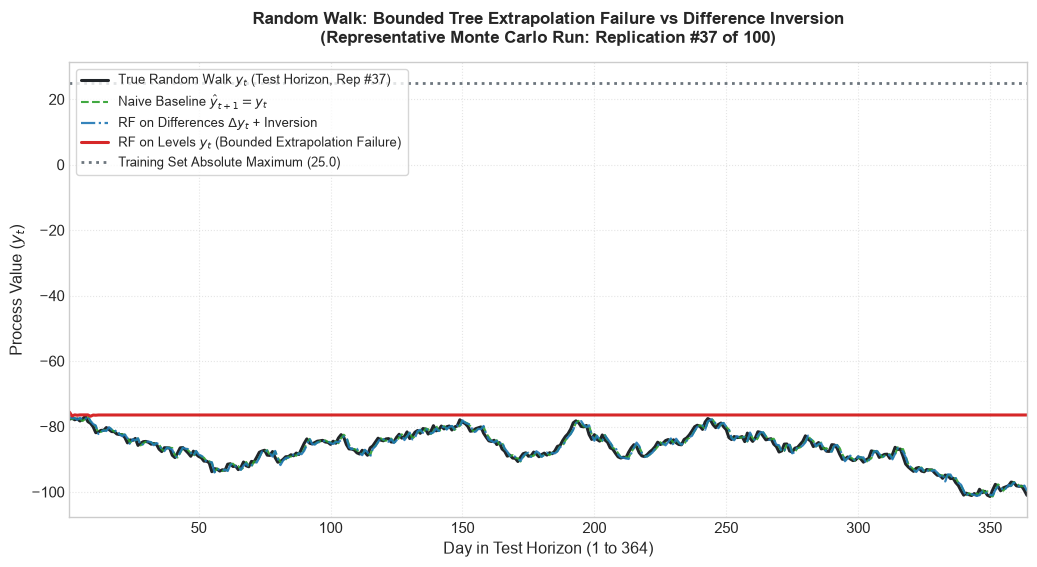

Saved: figures/simulations/rw_extrapolation_failure.png


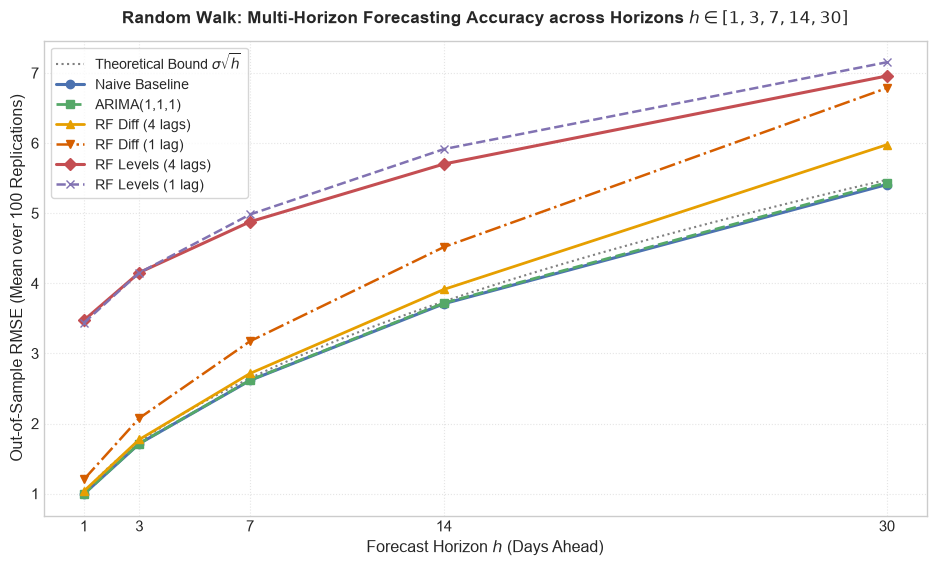

Saved: figures/simulations/rw_multistep_rmse.png


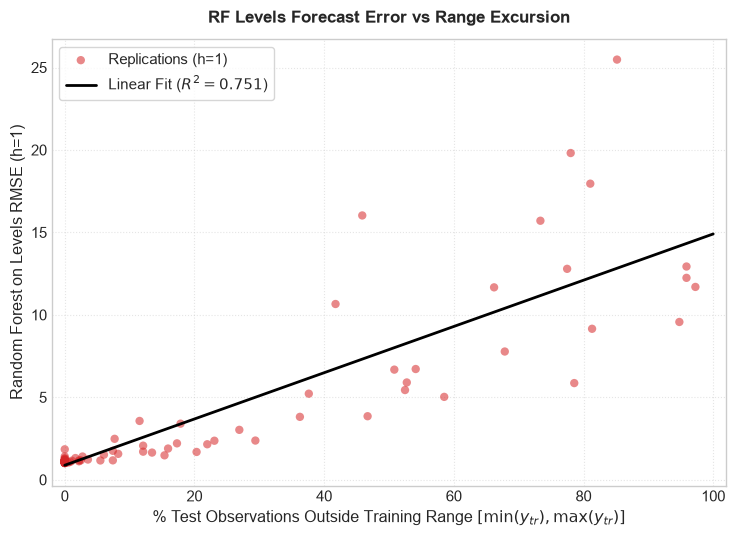

Saved: figures/simulations/rw_oob_scatter.png


In [4]:
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.titlesize": 12.5,
    "axes.titleweight": "bold",
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "figure.titlesize": 13,
    "grid.alpha": 0.5,
    "grid.linestyle": ":",
})

# 1. Figure 1: RW Visual Bounded Extrapolation Failure (Representative Single Run)
fig1, ax1 = plt.subplots(figsize=(10.5, 5.8))
best_rep = int(df_results["oob_rate"].argmax())
seed_rw = BASE_SEED + best_rep
y_rw = generate_random_walk(n_samples=N_SAMPLES, sigma=SIGMA, seed=seed_rw)
n_tr = N_SAMPLES - N_TEST
y_tr = y_rw.iloc[:n_tr]
y_te = y_rw.iloc[n_tr:]
days = np.arange(1, len(y_te) + 1)
max_tr = y_tr.max()
    min_tr = y_tr.min()

pred_naive = y_rw.shift(1).iloc[-N_TEST:].to_numpy()
pred_rflvl, _ = model_rf_levels_multistep(lags=[1, 2, 3, 4], n_estimators=100)(y_tr, y_rw, N_TEST, seed_rw, [1])
pred_rfdiff, _ = model_rf_diff_multistep(lags=[1, 2, 3, 4], d=1, n_estimators=100)(y_tr, y_rw, N_TEST, seed_rw, [1])

ax1.plot(days, y_te.to_numpy(), color="#212529", linewidth=2.2, label=f"True Random Walk $y_t$ (Test Horizon, Rep #{best_rep})")
ax1.plot(days, pred_naive, color="#2ca02c", linestyle="--", linewidth=1.5, alpha=0.9, label=r"Naive Baseline $\hat{y}_{t+1}=y_t$")
ax1.plot(days, pred_rfdiff[1], color="#1f77b4", linestyle="-.", linewidth=1.6, alpha=0.9, label=r"RF on Differences $\Delta y_t$ + Inversion")
ax1.plot(days, pred_rflvl[1], color="#d62728", linewidth=2.2, label=r"RF on Levels $y_t$ (Bounded Extrapolation Failure)")

ax1.axhline(max_tr, color="#6c757d", linestyle=":", linewidth=2, label=f"Training Set Absolute Maximum ({max_tr:.1f})")
    ax1.axhline(min_tr, color="#6c757d", linestyle=":", linewidth=2, label=f"Training Set Absolute Minimum ({min_tr:.1f})")

ax1.set_xlabel("Day in Test Horizon (1 to 364)")
ax1.set_ylabel("Process Value ($y_t$)")
ax1.legend(loc="upper left", frameon=True, fontsize=9.5)
ax1.set_xlim(1, N_TEST)

plt.tight_layout()
fig1_path = FIG_DIR / "rw_extrapolation_failure.png"
fig1.savefig(fig1_path, dpi=300)
plt.show()
print(f"Saved: {fig1_path}")

# 2. Figure 2: Multi-Horizon RMSE Evolution (Naive vs ARIMA vs RF Diff vs RF Levels)
fig2, ax2 = plt.subplots(figsize=(9.5, 5.8))

h_vals = HORIZONS
naive_means = [df_results[f"rmse_naive_h{h}"].mean() for h in h_vals]
arima_means = [df_results[f"rmse_arima111_h{h}"].mean() for h in h_vals]
rf_diff4_means = [df_results[f"rmse_rf_diff_4lags_h{h}"].mean() for h in h_vals]
rf_diff1_means = [df_results[f"rmse_rf_diff_1lag_h{h}"].mean() for h in h_vals]
rf_lvl4_means = [df_results[f"rmse_rf_lvl_4lags_h{h}"].mean() for h in h_vals]
rf_lvl1_means = [df_results[f"rmse_rf_lvl_1lag_h{h}"].mean() for h in h_vals]

h_dense = np.linspace(1, 30, 100)
ax2.plot(h_dense, SIGMA * np.sqrt(h_dense), color="gray", linestyle=":", linewidth=1.5, label=r"Theoretical Bound $\sigma \sqrt{h}$")

ax2.plot(h_vals, naive_means, marker="o", color="#4C72B0", linewidth=2.2, label="Naive Baseline")
ax2.plot(h_vals, arima_means, marker="s", color="#55A868", linestyle="--", linewidth=2.0, label="ARIMA(1,1,1)")
ax2.plot(h_vals, rf_diff4_means, marker="^", color="#E69F00", linewidth=2.0, label="RF Diff (4 lags)")
ax2.plot(h_vals, rf_diff1_means, marker="v", color="#D55E00", linestyle="-.", linewidth=1.8, label="RF Diff (1 lag)")
ax2.plot(h_vals, rf_lvl4_means, marker="D", color="#C44E52", linewidth=2.2, label="RF Levels (4 lags)")
ax2.plot(h_vals, rf_lvl1_means, marker="x", color="#8172B2", linestyle="--", linewidth=1.8, label="RF Levels (1 lag)")

ax2.set_xlabel("Forecast Horizon $h$ (Days Ahead)")
ax2.set_ylabel("Out-of-Sample RMSE (Mean over 100 Replications)")
ax2.set_title("Random Walk: Multi-Horizon Forecasting Accuracy across Horizons $h \in [1, 3, 7, 14, 30]$", pad=12)
ax2.set_xticks(h_vals)
ax2.legend(loc="upper left", frameon=True, fontsize=10)

plt.tight_layout()
fig2_path = FIG_DIR / "rw_multistep_rmse.png"
fig2.savefig(fig2_path, dpi=300)
plt.show()
print(f"Saved: {fig2_path}")

# 3. Figure 3: RW RF Levels RMSE vs Out-of-Bounds Rate (Linear Relationship at h=1)
fig3, ax3 = plt.subplots(figsize=(7.5, 5.5))
oob_pct = df_results["oob_rate"] * 100
rmse_lvl = df_results["rmse_rf_lvl_4lags_h1"]

ax3.scatter(oob_pct, rmse_lvl, alpha=0.55, color="#d62728", edgecolors="none", s=36, label="Replications (h=1)")
slope, intercept, r_val, p_val, _ = stats.linregress(oob_pct, rmse_lvl)
x_line = np.linspace(0, 100, 100)
ax3.plot(x_line, intercept + slope * x_line, color="black", linewidth=2, label=f"Linear Fit ($R^2 = {r_val**2:.3f}$)")

ax3.set_xlabel("% Test Observations Outside Training Range $[\min(y_{tr}), \max(y_{tr})]$")
ax3.set_ylabel("Random Forest on Levels RMSE (h=1)")
ax3.set_title("RF Levels Forecast Error vs Range Excursion", pad=12)
ax3.set_xlim(-2, 102)
ax3.legend(loc="upper left", frameon=True)

plt.tight_layout()
fig3_path = FIG_DIR / "rw_oob_scatter.png"
fig3.savefig(fig3_path, dpi=300)
plt.show()
print(f"Saved: {fig3_path}")
